# Søvn/våken-klassifisering fra Apple Watch (akselerometer + puls)

**Datasett:** PhysioNet «Motion and heart rate from a wrist-worn wearable and labeled sleep from polysomnography», v1.0.0 (ODC-By v1.0). Fullstendig kildehenvisning står i README.md.

**Mål:** Binær klassifisering av 30-sekunders epoker: våken (0) mot søvn (1), med polysomnografi (PSG) som referansestandard.

**Tidsangivelse:** Alle tidsstempler er sekunder fra PSG-start. Negative verdier er data fra dagene før laboratorienatten.

**Oppbygging:** (1) konfigurasjon og inventar, (2) kvalitetskontroll og eksklusjon, (3) bygging av epoketabell, (4) deltakerbasert datadeling og baseline-modeller.

## 1. Konfigurasjon
Alle parametere samles her slik at analysen kan gjentas. Eksklusjonsterskelen (`COVERAGE_MIN`) og grensen for lav samplingrate (`LOW_RATE_HZ`) er satt før modellering, slik at de ikke påvirkes av modellresultater. Separatorene er kontrollert i terminalen: labelfiler og akselerometerfiler er mellomromseparerte, pulsfiler er kommaseparerte.

In [1]:
import os, glob, time
import numpy as np
import pandas as pd

SEED = 42
EPOCH_SEC = 30
DATA_DIR = '.'
HR_FFILL_LIMIT = 10        # maks antall epoker (5 min) en pulsverdi kan videreføres
COVERAGE_MIN = 0.5         # eksklusjon: andel skårede epoker med akselerometerdata
LOW_RATE_HZ = 15           # under dette flagges deltakeren for sensitivitetsanalyse
VALID_STAGES = {-1, 0, 1, 2, 3, 4, 5}   # stadier som forekommer i labelfilene

SEP = {'labels': r'\s+', 'accel': r'\s+', 'hr': ','}

print('pandas', pd.__version__, '| numpy', np.__version__)
print(sorted(os.listdir(DATA_DIR)))

pandas 3.0.5 | numpy 2.4.6
['.git', '.gitignore', '.ipynb_checkpoints', 'README.md', 'coverage_qc.csv', 'final_project_laho.ipynb', 'heart_rate', 'labels', 'master_matrix.parquet', 'motion']


## 2. Inventar
Kontrollerer at alle tre filtyper finnes for hver deltaker, og at ingen akselerometerfiler har uvanlig størrelse. Filstørrelsen varierer med samplingraten og opptakslengden, så den alene sier ikke om en fil er avkortet. Det avgjøres i dekningskontrollen under.

In [2]:
def paths(sid):
    return dict(
        labels=os.path.join(DATA_DIR, 'labels',     f'{sid}_labeled_sleep.txt'),
        accel =os.path.join(DATA_DIR, 'motion',     f'{sid}_acceleration.txt'),
        hr    =os.path.join(DATA_DIR, 'heart_rate', f'{sid}_heartrate.txt'),
    )

subject_ids = sorted(os.path.basename(p).split('_')[0]
                     for p in glob.glob(os.path.join(DATA_DIR, 'labels', '*_labeled_sleep.txt')))

inv = pd.DataFrame({s: {k: os.path.exists(v) for k, v in paths(s).items()} for s in subject_ids}).T
inv['accel_MB'] = [os.path.getsize(paths(s)['accel']) / 1e6 for s in inv.index]
print(len(subject_ids), 'deltakere med labelfil')
print('Deltakere med manglende filer:', list(inv.index[~inv[['labels', 'accel', 'hr']].all(axis=1)]))
inv['accel_MB'].describe().round(1)

31 deltakere med labelfil
Deltakere med manglende filer: []


count     31.0
mean      75.6
std       63.3
min       13.5
25%       56.3
50%       71.8
75%       78.8
max      399.4
Name: accel_MB, dtype: float64

## 3. Innlesingsfunksjoner
Filene er store (ca. 2,2 GB akselerometerdata), så de leses med pandas' raske C-parser og én fast separator per filtype. `read_table` fjerner rader som ikke kan tolkes som tall. `read_col0` leser bare tidskolonnen og brukes i dekningskontrollen.

In [3]:
def read_table(path, names, sep):
    df = pd.read_csv(path, sep=sep, names=names, header=None,
                     usecols=range(len(names)), on_bad_lines='skip')
    return df.apply(pd.to_numeric, errors='coerce').dropna().reset_index(drop=True)

def read_col0(path, sep):
    return (pd.read_csv(path, sep=sep, header=None, usecols=[0], dtype='float64',
                        on_bad_lines='skip').iloc[:, 0].dropna().to_numpy())

## 4. Kvalitetskontroll: akselerometerdekning, samplingrate og tidsstempler
For hver deltaker beregnes:
- **dekning:** andel av de skårede PSG-epokene (stadium ≠ −1) som har minst én akselerometermåling,
- **hz:** gjennomsnittlig samplingrate innenfor PSG-vinduet (inkluderer eventuelle hull),
- **største hull:** lengste periode uten målinger innenfor PSG-vinduet,
- **bakover-steg og duplikate tidsstempler:** kontroll av rekkefølgen i tidsstemplene.

Deltakere med dekning under `COVERAGE_MIN` ekskluderes. Deltakere med lav samplingrate beholdes, men flagges for sensitivitetsanalyse, siden varians av akselerasjon ikke er fullt sammenlignbar mellom ulike samplingrater.

In [4]:
rows = []
for sid in subject_ids:
    p = paths(sid)
    lab = read_table(p['labels'], ['t', 'stage'], SEP['labels'])
    lab['epoch'] = (lab['t'] // EPOCH_SEC).astype(int)
    scored = set(lab.loc[lab['stage'] != -1, 'epoch'])
    t_end = lab['t'].max()

    t = read_col0(p['accel'], SEP['accel'])
    inside = t[(t >= 0) & (t <= t_end)]
    covered = len(scored & set(np.unique((inside // EPOCH_SEC).astype(int))))

    ti = np.concatenate([[0], np.sort(inside), [t_end]])
    rows.append(dict(
        subject=sid,
        psg_timer=round(t_end / 3600, 2),
        hz=round(len(inside) / t_end, 1),
        dekning=round(covered / len(scored), 3),
        storste_hull_min=round(np.diff(ti).max() / 60, 1),
        bakover_steg=int((np.diff(t) < 0).sum()),
        duplikate_tid=int(len(t) - len(np.unique(t))),
        utenfor_psg=int(len(t) - len(inside)),
    ))
    print(sid, 'ok', flush=True)

cov = pd.DataFrame(rows).set_index('subject').sort_values('dekning')
display(cov)

EXCLUDE = list(cov.index[cov['dekning'] < COVERAGE_MIN])
LOW_RATE = list(cov.index[(cov['hz'] < LOW_RATE_HZ) & ~cov.index.isin(EXCLUDE)])
print('Ekskluderes (dekning <', COVERAGE_MIN, '):', EXCLUDE)
print('Lav samplingrate (sensitivitetsanalyse):', LOW_RATE)
cov.to_csv('coverage_qc.csv')    # ignoreres av Git

1066528 ok
1360686 ok
1449548 ok
1455390 ok
1818471 ok
2598705 ok
2638030 ok
3509524 ok
3997827 ok
4018081 ok
4314139 ok
4426783 ok
46343 ok
5132496 ok
5383425 ok
5498603 ok
5797046 ok
6220552 ok
759667 ok
7749105 ok
781756 ok
8000685 ok
8173033 ok
8258170 ok
844359 ok
8530312 ok
8686948 ok
8692923 ok
9106476 ok
9618981 ok
9961348 ok


,psg_timer,hz,dekning,storste_hull_min,bakover_steg,duplikate_tid,utenfor_psg
subject,,,,,,,
7749105,7.99,7.7,0.126,412.4,0,0,199502
1066528,7.92,41.6,0.870,21.3,0,0,93097
2598705,8.18,49.0,0.921,3.2,42,0,149662
1449548,8.03,56.0,0.929,12.4,93,0,190813
8530312,8.04,53.0,0.938,8.2,1,0,149570
759667,3.95,61.2,0.954,10.6,0,0,317059
4018081,4.24,63.2,0.975,5.5,2,0,121924
1360686,8.06,47.7,0.976,20.9,30,0,174109
8000685,8.03,49.3,0.993,3.0,80,0,227145


Ekskluderes (dekning < 0.5 ): ['7749105']
Lav samplingrate (sensitivitetsanalyse): ['5383425', '8258170']


## 5. Kvalitetskontroll: PSG-stadier
PSG-beskrivelsen oppgir stadiene 0 (våken), 1 (N1), 2 (N2), 3 (N3) og 5 (REM). Her kontrolleres hvilke stadier som faktisk finnes per deltaker, og hvor epoker med stadium −1 ligger (i begynnelsen, i slutten eller midt i natten). Stadium −1 er ikke definert i datasettbeskrivelsen og behandles som uskåret. Stadium 4 forekommer hos enkelte deltakere og er heller ikke definert i beskrivelsen. For våken/søvn-målet regnes det som søvn (stadium ≠ 0).

In [5]:
stage_counts, raw = {}, {}
for sid in subject_ids:
    d = read_table(paths(sid)['labels'], ['t', 'stage'], SEP['labels'])
    d['stage'] = d['stage'].astype(int)
    stage_counts[sid] = d['stage'].value_counts()
    m = d['stage'].eq(-1)
    first, last = d.index[~m].min(), d.index[~m].max()
    raw[sid] = dict(n_minus1=int(m.sum()),
                    i_starten=int(m[:first].sum()),
                    i_slutten=int(m[last + 1:].sum()),
                    midt_i_natten=int(m[first:last + 1].sum()))

stages = pd.DataFrame(stage_counts).T.fillna(0).astype(int).sort_index(axis=1)
minus1 = pd.DataFrame(raw).T

print('Stadier i datasettet:', list(stages.columns))
print('Deltakere med stadium 4:', list(stages.index[stages.get(4, 0) > 0]))
display(stages[stages[4] > 0] if 4 in stages.columns else stages.head())
display(minus1.sort_values('midt_i_natten', ascending=False).head(10))
print('Epoker med -1 midt i natten totalt:', minus1['midt_i_natten'].sum())

Stadier i datasettet: [-1, 0, 1, 2, 3, 4, 5]
Deltakere med stadium 4: ['5383425', '8258170', '9618981']


stage,-1,0,1,2,3,4,5
5383425,2,40,52,391,34,190,269
8258170,0,95,48,400,49,83,297
9618981,0,94,165,348,25,83,230


,n_minus1,i_starten,i_slutten,midt_i_natten
5383425,2,0,0,2
8530312,19,16,1,2
1449548,12,11,0,1
5797046,23,22,0,1
8000685,8,5,2,1
1455390,35,34,1,0
1066528,0,0,0,0
2638030,21,13,8,0
3509524,0,0,0,0
4018081,0,0,0,0


Epoker med -1 midt i natten totalt: 7


## 6. Prosessering per deltaker
For hver deltaker beregnes én rad per 30-sekunders epoke:
- **Akselerometer:** vektormagnitude √(x²+y²+z²), deretter varians, gjennomsnitt og maksimum per epoke. Epoker uten måling får `accel_missing = 1` og fylles ikke med 0, siden «ingen måling» ikke er det samme som «ingen bevegelse».
- **Puls:** gjennomsnitt og standardavvik per epoke. Manglende epoker fylles bare fremover i tid (forward-fill), maksimalt `HR_FFILL_LIMIT` epoker, slik at ingen fremtidig informasjon brukes. Fylte epoker flagges (`hr_imputed`).
- **Målvariabel:** våken (stadium 0) = 0, søvn (øvrige stadier) = 1. Epoker med stadium −1 fjernes til slutt, slik at tidsgrunnlaget er sammenhengende under koblingen. Den opprinnelige `stage`-verdien beholdes.
- Alle tre kilder kobles på epokeindeks (tid delt på 30, rundet ned).

In [6]:
def process_subject(sid):
    p = paths(sid)
    if not all(os.path.exists(v) for v in p.values()):
        return None

    lab = read_table(p['labels'], ['t', 'stage'], SEP['labels'])
    lab['stage'] = lab['stage'].astype(int)
    lab['epoch'] = (lab['t'] // EPOCH_SEC).astype(int)
    lab = lab.drop_duplicates('epoch')[['epoch', 'stage']]
    unexpected = set(lab['stage'].unique()) - VALID_STAGES
    assert not unexpected, f'{sid}: uventede stadier {unexpected}'

    acc = read_table(p['accel'], ['t', 'x', 'y', 'z'], SEP['accel'])
    acc['mag'] = np.sqrt(acc['x']**2 + acc['y']**2 + acc['z']**2)
    acc['epoch'] = (acc['t'] // EPOCH_SEC).astype(int)
    acc_f = acc.groupby('epoch')['mag'].agg(accel_var='var', accel_mean='mean',
                                            accel_max='max', accel_n='size')

    hr = read_table(p['hr'], ['t', 'hr'], SEP['hr'])
    hr['epoch'] = (hr['t'] // EPOCH_SEC).astype(int)
    hr_f = hr.groupby('epoch')['hr'].agg(hr_mean='mean', hr_std='std', hr_n='size')

    df = (lab.merge(acc_f, on='epoch', how='left')
             .merge(hr_f,  on='epoch', how='left')
             .sort_values('epoch').reset_index(drop=True))

    df['accel_missing'] = df['accel_var'].isna().astype(int)
    df['log_accel_var'] = np.log1p(df['accel_var'])

    df['hr_imputed'] = df['hr_mean'].isna().astype(int)
    df['hr_mean'] = df['hr_mean'].ffill(limit=HR_FFILL_LIMIT)
    df['hr_still_missing'] = df['hr_mean'].isna().astype(int)

    df = df[df['stage'] != -1].copy()
    df['label'] = (df['stage'] != 0).astype(int)      # 0 = våken, 1 = søvn
    df.insert(0, 'subject_id', str(sid))
    return df

## 7. Epoketabell for alle deltakere
Kjører prosesseringen for hver deltaker som ikke er ekskludert i kvalitetskontrollen, og samler resultatet i én tabell (`master`) der hver rad er én 30-sekunders epoke for én deltaker. Deltakere med lav samplingrate flagges i kolonnen `low_rate`. Tabellen lagres som parquet-fil som ikke versjonskontrolleres.

In [7]:
frames, skipped = [], []
for sid in subject_ids:
    if sid in EXCLUDE:
        skipped.append((sid, f'dekning {cov.loc[sid, "dekning"]} < {COVERAGE_MIN}')); continue
    t0 = time.time()
    try:
        df = process_subject(sid)
    except Exception as e:
        skipped.append((sid, repr(e))); continue
    if df is None:
        skipped.append((sid, 'manglende fil')); continue
    frames.append(df)
    print(f'{sid}: {len(df)} epoker ({time.time() - t0:.1f} s)', flush=True)

master = pd.concat(frames, ignore_index=True)
master['low_rate'] = master['subject_id'].isin(LOW_RATE)
print('\nHoppet over:', skipped)
print(f"{master['subject_id'].nunique()} deltakere, {len(master):,} epoker")
master.to_parquet('master_matrix.parquet')    # krever pyarrow

1066528: 952 epoker (0.9 s)
1360686: 948 epoker (1.0 s)
1449548: 953 epoker (1.1 s)
1455390: 955 epoker (1.0 s)
1818471: 958 epoker (1.0 s)
2598705: 954 epoker (1.0 s)
2638030: 948 epoker (1.2 s)
3509524: 417 epoker (0.8 s)
3997827: 958 epoker (1.2 s)
4018081: 510 epoker (0.8 s)
4314139: 961 epoker (1.1 s)
4426783: 980 epoker (1.2 s)
46343: 554 epoker (0.7 s)
5132496: 465 epoker (0.8 s)
5383425: 976 epoker (0.2 s)
5498603: 744 epoker (0.9 s)
5797046: 939 epoker (1.2 s)
6220552: 955 epoker (1.2 s)
759667: 475 epoker (0.7 s)
781756: 981 epoker (1.0 s)
8000685: 957 epoker (1.0 s)
8173033: 955 epoker (1.0 s)
8258170: 972 epoker (0.2 s)
844359: 897 epoker (0.9 s)
8530312: 947 epoker (1.0 s)
8686948: 955 epoker (0.9 s)
8692923: 936 epoker (1.2 s)
9106476: 961 epoker (1.1 s)
9618981: 945 epoker (6.0 s)
9961348: 720 epoker (1.0 s)

Hoppet over: [('7749105', 'dekning 0.126 < 0.5')]
30 deltakere, 25,828 epoker


## 8. Kvalitetskontroll av epoketabellen
Oppsummerer per deltaker: antall epoker, andel søvn (klasseubalanse), andel epoker uten akselerometerdata, andel epoker med fylt puls, og andel epoker som fortsatt mangler puls etter fyllingen. `maks_epoke_hull` over 1 betyr at epoker med stadium −1 er fjernet midt i natten. Dette bestemmer om enkelte deltakere har så mange manglende verdier at de bør vurderes ekskludert, og om klassefordelingen krever hensyn i evalueringen.

In [8]:
qc = master.groupby('subject_id').agg(
    epoker=('label', 'size'),
    andel_sovn=('label', 'mean'),
    andel_accel_mangler=('accel_missing', 'mean'),
    andel_hr_imputert=('hr_imputed', 'mean'),
    andel_hr_mangler_fortsatt=('hr_still_missing', 'mean'),
    median_hr=('hr_mean', 'median'),
    maks_epoke_hull=('epoch', lambda s: s.diff().max()),
)
display(qc.round(3))
print('Total andel søvn:', master['label'].mean().round(3))
print(master['stage'].value_counts().sort_index())

,epoker,andel_sovn,andel_accel_mangler,andel_hr_imputert,andel_hr_mangler_fortsatt,median_hr,maks_epoke_hull
subject_id,,,,,,,
1066528,952,0.806,0.130,0.081,0.021,59.333,1.0
1360686,948,0.877,0.024,0.000,0.000,69.667,1.0
1449548,953,0.890,0.070,0.000,0.000,68.000,2.0
1455390,955,0.912,0.000,0.001,0.000,52.333,1.0
1818471,958,0.990,0.000,0.000,0.000,76.333,1.0
2598705,954,0.979,0.079,0.031,0.000,48.500,1.0
2638030,948,0.870,0.000,0.000,0.000,57.243,1.0
3509524,417,0.873,0.000,0.000,0.000,90.000,1.0
3997827,958,0.974,0.000,0.000,0.000,53.333,1.0


Total andel søvn: 0.914
stage
0     2224
1     1796
2    12590
3     3196
4      356
5     5666
Name: count, dtype: int64


## 9. Deltakerbasert deling i trenings- og testsett
Epoker fra samme deltaker er sterkt korrelerte. Hvis de havner i både trenings- og testsett, blir resultatene urealistisk gode (data leakage). Deling skjer derfor på deltakernivå: hele deltakere er enten i treningssettet eller i testsettet. Dette tilsvarer den kliniske situasjonen der modellen brukes på personer den ikke har sett. Testsettet brukes ikke før modellvalget er ferdig.

In [9]:
from sklearn.model_selection import GroupShuffleSplit

feature_cols = ['log_accel_var', 'accel_mean', 'accel_max', 'hr_mean', 'hr_std',
                'accel_missing', 'hr_imputed']
X, y, groups = master[feature_cols], master['label'], master['subject_id']

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr, te = next(gss.split(X, y, groups))
X_tr, y_tr, g_tr = X.iloc[tr], y.iloc[tr], groups.iloc[tr]
X_te, y_te, g_te = X.iloc[te], y.iloc[te], groups.iloc[te]
assert set(g_tr).isdisjoint(set(g_te))
print('Trening:', g_tr.nunique(), 'deltakere | Test:', g_te.nunique(), 'deltakere')
print('Søvnandel trening/test:', y_tr.mean().round(3), y_te.mean().round(3))
print('Lav samplingrate i test:', sorted(set(g_te) & set(LOW_RATE)))

Trening: 24 deltakere | Test: 6 deltakere
Søvnandel trening/test: 0.915 0.909
Lav samplingrate i test: []


## 10. Baseline og kryssvalidering (kun treningssettet)
Siden søvn dominerer datasettet, er ren accuracy misvisende: en modell som alltid svarer «søvn» ville se god ut. Modellene vurderes derfor med balansert accuracy, sensitivitet for søvn, spesifisitet for våken, F1 og Cohens kappa. Majoritetsklassifikatoren er nedre grense. Logistisk regresjon er første reelle modell. Imputering og skalering ligger i en pipeline, slik at de læres fra treningsfoldene alene. Kryssvalideringen er gruppert på deltaker.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, recall_score, cohen_kappa_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def report(y_true, y_pred):
    return dict(
        bal_acc=balanced_accuracy_score(y_true, y_pred),
        sensitivitet_sovn=recall_score(y_true, y_pred, pos_label=1),
        spesifisitet_vaken=recall_score(y_true, y_pred, pos_label=0),
        f1_sovn=f1_score(y_true, y_pred, pos_label=1),
        kappa=cohen_kappa_score(y_true, y_pred),
    )

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    'Majoritetsklasse': DummyClassifier(strategy='most_frequent'),
    'Logistisk regresjon': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                         LogisticRegression(class_weight='balanced', max_iter=1000)),
}
rows, preds = {}, {}
for name, m in models.items():
    preds[name] = cross_val_predict(m, X_tr, y_tr, groups=g_tr, cv=cv)
    rows[name] = report(y_tr, preds[name])
display(pd.DataFrame(rows).T.round(3))

,bal_acc,sensitivitet_sovn,spesifisitet_vaken,f1_sovn,kappa
Majoritetsklasse,0.500,1.000,0.000,0.956,0.000
Logistisk regresjon,0.663,0.899,0.426,0.921,0.264


## 11. Kontroller før videre modellering
Tre kontroller som avgjør hvordan resultatene kan tolkes:
1. **Antall våkne epoker per deltaker.** Våken utgjør en liten andel av epokene, og enkelte deltakere har svært få. Spesifisitet per deltaker er upålitelig når det er få våkne epoker.
2. **Sammenheng mellom manglende akselerometerdata og målvariabel.** Hvis manglende data oftere forekommer i én klasse, kan indikatoren `accel_missing` gi modellen informasjon som ikke er fysiologisk.
3. **Pulsvariabilitet.** Standardavviket for puls er udefinert for epoker med én enkelt pulsmåling, så andelen manglende verdier og pulssamplingen kontrolleres.

In [11]:
wake = master.groupby('subject_id')['label'].agg(
    epoker='size', n_vaken=lambda s: int((s == 0).sum()))
wake['min_vaken'] = wake['n_vaken'] / 2
display(wake.sort_values('n_vaken').head(8))
print('Testdeltakere:'); display(wake.loc[sorted(set(g_te))])

print(master.groupby('accel_missing')['label'].agg(['size', 'mean']).round(3))

print('Andel epoker uten hr_std:', master['hr_std'].isna().mean().round(3))
print(master.groupby('subject_id')['hr_n'].median().describe().round(1))

,epoker,n_vaken,min_vaken
subject_id,,,
1818471,958,10,5.0
759667,475,18,9.0
2598705,954,20,10.0
3997827,958,25,12.5
8173033,955,29,14.5
8000685,957,33,16.5
5132496,465,33,16.5
5383425,976,40,20.0


Testdeltakere:


,epoker,n_vaken,min_vaken
subject_id,,,
3997827,958,25,12.5
4018081,510,91,45.5
5498603,744,107,53.5
6220552,955,53,26.5
844359,897,93,46.5
9106476,961,87,43.5


                size   mean
accel_missing              
0              25436  0.916
1                392  0.791
Andel epoker uten hr_std: 0.005
count    30.0
mean      7.2
std       3.7
min       6.0
25%       6.0
50%       6.0
75%       6.0
max      18.0
Name: hr_n, dtype: float64


## 12. Resultater per deltaker og med våken som positiv klasse
Samlede resultater (pooled) vektlegger deltakere med mange epoker og skjuler variasjon mellom personer. Her vises sensitivitet, spesifisitet og accuracy per deltaker, sammen med presisjon, recall, F1 og MCC for klassen våken. Deltakere med få våkne epoker tolkes med forsiktighet.

In [12]:
from sklearn.metrics import matthews_corrcoef, precision_score

name = 'Logistisk regresjon'
res = pd.DataFrame({'subject': g_tr.values, 'y': y_tr.values, 'p': preds[name]})

def metrics_row(d):
    nw, ns = (d.y == 0).sum(), (d.y == 1).sum()
    return dict(n_vaken=nw,
                sens_sovn=(d.p[d.y == 1] == 1).mean() if ns else np.nan,
                spes_vaken=(d.p[d.y == 0] == 0).mean() if nw else np.nan,
                acc=(d.p == d.y).mean())

per = pd.DataFrame({s: metrics_row(d) for s, d in res.groupby('subject')}).T.astype(float)
display(per.sort_values('spes_vaken').round(3))
print('Median spesifisitet (≥ 30 våkne epoker):',
      round(per.loc[per.n_vaken >= 30, 'spes_vaken'].median(), 3))

yp = preds[name]
print('Våken som positiv klasse: presisjon', round(precision_score(y_tr, yp, pos_label=0), 3),
      '| recall', round(recall_score(y_tr, yp, pos_label=0), 3),
      '| F1', round(f1_score(y_tr, yp, pos_label=0), 3),
      '| MCC', round(matthews_corrcoef(y_tr, yp), 3))

,n_vaken,sens_sovn,spes_vaken,acc
8258170,95.0,0.892,0.242,0.828
1360686,117.0,0.963,0.274,0.878
1066528,185.0,0.860,0.292,0.750
1455390,84.0,0.976,0.310,0.917
8692923,110.0,0.941,0.318,0.868
46343,85.0,0.985,0.353,0.888
9618981,94.0,0.964,0.426,0.910
2638030,123.0,0.962,0.439,0.895
3509524,53.0,0.978,0.453,0.911
5132496,33.0,0.785,0.455,0.761


Median spesifisitet (≥ 30 våkne epoker): 0.461
Våken som positiv klasse: presisjon 0.281 | recall 0.426 | F1 0.339 | MCC 0.271


## 13. Sensitivitetsanalyse
Samme modell og kryssvalidering kjøres på delmengder av treningsdataene for å se om enkeltdeltakere med avvikende datakvalitet påvirker resultatet: (a) uten de to deltakerne med ca. 10 Hz akselerometer, og (b) uten `1066528` (lavest akselerometerdekning av de inkluderte). Med få deltakere gir ulik foldinndeling i seg selv noe støy, så små forskjeller bør ikke overtolkes.

In [13]:
def cv_report(mask, label):
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                      LogisticRegression(class_weight='balanced', max_iter=1000))
    cv_ = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    p = cross_val_predict(m, X_tr[mask], y_tr[mask], groups=g_tr[mask], cv=cv_)
    return {label: report(y_tr[mask], p)}

out = {}
out.update(cv_report(pd.Series(True, index=g_tr.index), 'Alle treningsdeltakere'))
out.update(cv_report(~g_tr.isin(LOW_RATE), 'Uten lav samplingrate'))
out.update(cv_report(g_tr != '1066528', 'Uten 1066528'))
display(pd.DataFrame(out).T.round(3))

,bal_acc,sensitivitet_sovn,spesifisitet_vaken,f1_sovn,kappa
Alle treningsdeltakere,0.663,0.899,0.426,0.921,0.264
Uten lav samplingrate,0.674,0.882,0.467,0.913,0.263
Uten 1066528,0.673,0.902,0.443,0.925,0.274


## 14. Tidskontekst-features
Én epoke alene gir «blips» av søvn og våken, mens søvn og våken varer i minutter. Derfor beregnes rullerende gjennomsnitt og standardavvik av akselerasjon og puls over nabo-epoker (5 epoker = 2,5 min, 11 epoker = 5,5 min), sentrert og **innenfor hver deltaker**. Beregningen bruker epokeindeksen, ikke radposisjonen, slik at fjernede −1-epoker ikke behandles som om nabo-epokene lå inntil hverandre. Sentrerte vinduer bruker også fremtidige epoker, noe som er greit for en offline-klassifikator, men må nevnes som begrensning. Pulsavvik fra deltakerens egen median (`hr_rel`) fjerner nivåforskjeller mellom personer, men bruker hele natten og er ikke kausal. Ingen av featurene bruker labels.

In [14]:
def add_context(master, cols=('log_accel_var', 'hr_mean'), windows=(5, 11)):
    out = []
    for sid, d in master.groupby('subject_id', sort=False):
        g = d.set_index('epoch')
        grid = g[list(cols)].reindex(range(int(g.index.min()), int(g.index.max()) + 1))
        for c in cols:
            for w in windows:
                r = grid[c].rolling(w, center=True, min_periods=1)
                g[f'{c}_m{w}'] = r.mean().reindex(g.index)
                g[f'{c}_s{w}'] = r.std().reindex(g.index)
        g['hr_rel'] = g['hr_mean'] - g['hr_mean'].median()
        out.append(g.reset_index())
    return pd.concat(out, ignore_index=True)

master2 = add_context(master)
# radrekkefølgen må være uendret, slik at train/test-indeksene fortsatt gjelder
assert (master2['subject_id'].values == master['subject_id'].values).all()
assert (master2['epoch'].values == master['epoch'].values).all()

ctx = [c for c in master2.columns
       if c.startswith(('log_accel_var_m', 'log_accel_var_s', 'hr_mean_m', 'hr_mean_s'))]
print(len(ctx), 'kontekst-features:', ctx)

8 kontekst-features: ['log_accel_var_m5', 'log_accel_var_s5', 'log_accel_var_m11', 'log_accel_var_s11', 'hr_mean_m5', 'hr_mean_s5', 'hr_mean_m11', 'hr_mean_s11']


## 15. Hvor ligger epokene uten akselerometerdata?
Epoker uten akselerometerdata har høyere andel våken enn øvrige epoker. Hvis de ligger hovedsakelig i begynnelsen eller slutten av natten, kan `accel_missing` fange opp tid på natten og opptaksartefakter, ikke fysiologi. Posisjonen vises som andel av opptakets lengde (0 = første epoke, 1 = siste).

In [15]:
pos = master2.groupby('subject_id')['epoch'].transform(
    lambda s: (s - s.min()) / (s.max() - s.min()))
print(pos[master2['accel_missing'] == 1].describe().round(3))
print(master2[master2['accel_missing'] == 1].groupby('subject_id').size().sort_values(ascending=False).head(8))

count    392.000
mean       0.679
std        0.264
min        0.000
25%        0.524
50%        0.741
75%        0.885
max        1.000
Name: epoch, dtype: float64
subject_id
1066528    124
2598705     75
1449548     67
8530312     59
1360686     23
759667      21
4018081     12
8000685      7
dtype: int64


## 16. Sammenligning av featuresett og modeller (kun treningssettet)
Fire featuresett sammenlignes med deltakergruppert kryssvalidering: (A) enkeltepoker, (B) enkeltepoker uten `accel_missing`, (C) med tidskontekst, (D) med tidskontekst og deltakernormalisert puls. To modeller brukes: logistisk regresjon og gradient boosting. Begge bruker `class_weight='balanced'` for å ta hensyn til klasseubalansen. Samme folder brukes for alle kombinasjoner, slik at forskjellene er sammenlignbare. Testsettet brukes ikke.

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier

base = ['log_accel_var', 'accel_mean', 'accel_max', 'hr_mean', 'hr_std', 'accel_missing', 'hr_imputed']
base_nomiss = [c for c in base if c != 'accel_missing']
ctx_cols = [c for c in master2.columns
            if c.startswith(('log_accel_var_m', 'log_accel_var_s', 'hr_mean_m', 'hr_mean_s'))]

sets = {
    'A enkeltepoker':               base,
    'B uten accel_missing':         base_nomiss,
    'C + tidskontekst':             base_nomiss + ctx_cols,
    'D + tidskontekst + hr_rel':    base_nomiss + ctx_cols + ['hr_rel'],
}
models2 = {
    'LogReg': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                            LogisticRegression(class_weight='balanced', max_iter=1000)),
    'HistGB': HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED),
}

Xtr2 = master2.iloc[tr]
rows = {}
for sname, cols in sets.items():
    for mname, m in models2.items():
        p = cross_val_predict(m, Xtr2[cols], y_tr, groups=g_tr, cv=cv)
        rows[(sname, mname)] = report(y_tr, p)
        print(sname, mname, 'ferdig', flush=True)
display(pd.DataFrame(rows).T.round(3))

A enkeltepoker LogReg ferdig
A enkeltepoker HistGB ferdig
B uten accel_missing LogReg ferdig
B uten accel_missing HistGB ferdig
C + tidskontekst LogReg ferdig
C + tidskontekst HistGB ferdig
D + tidskontekst + hr_rel LogReg ferdig
D + tidskontekst + hr_rel HistGB ferdig


bal_acc  sensitivitet_sovn  \
A enkeltepoker            LogReg    0.663              0.899   
                          HistGB    0.642              0.797   
B uten accel_missing      LogReg    0.665              0.905   
                          HistGB    0.642              0.797   
C + tidskontekst          LogReg    0.732              0.891   
                          HistGB    0.718              0.873   
D + tidskontekst + hr_rel LogReg    0.734              0.890   
                          HistGB    0.711              0.890   

                                  spesifisitet_vaken  f1_sovn  kappa  
A enkeltepoker            LogReg               0.426    0.921  0.264  
                          HistGB               0.486    0.864  0.161  
B uten accel_missing      LogReg               0.425    0.924  0.274  
                          HistGB               0.486    0.864  0.161  
C + tidskontekst          LogReg               0.572    0.923  0.347  
                          HistGB               0.563    0.913  0.307  
D + tidskontekst + hr_rel LogReg               0.578    0.923  0.348  
                          HistGB               0.532    0.921  0.318

## 17. Gjentatt kryssvalidering med terskeluavhengige mål
Resultatene fra én foldinndeling varierer med hvordan deltakerne fordeles på folder. Her gjentas kryssvalideringen med fem ulike tilfeldige fordelinger av deltakerne (gruppert på deltaker, slik at en deltaker aldri er i både trening og validering), og gjennomsnitt og standardavvik rapporteres. Standardavviket beskriver variasjon mellom foldinndelinger, ikke mellom nye deltakere, og er derfor ikke et konfidensintervall. I tillegg beregnes AUC og gjennomsnittlig presisjon (AP) for klassen våken, som ikke avhenger av klassifiseringsterskelen. Det gjør modellene sammenlignbare selv om de gir ulik balanse mellom sensitivitet og spesifisitet ved standardterskelen 0,5.

In [17]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import cross_val_predict

def make_group_folds(groups, n_splits=5, seed=0):
    """Fordeler hele deltakere tilfeldig på folder. Ulike frø gir ulike foldinndelinger."""
    rng = np.random.RandomState(seed)
    subj = np.array(sorted(set(groups)))
    rng.shuffle(subj)
    fold_of = {s: i % n_splits for i, s in enumerate(subj)}
    fold = np.array([fold_of[g] for g in groups])
    return [(np.where(fold != k)[0], np.where(fold == k)[0]) for k in range(n_splits)]

def repeated_cv(cols, model, X_all, seeds=(0, 1, 2, 3, 4)):
    out = []
    for s in seeds:
        folds = make_group_folds(g_tr.values, 5, s)
        p = cross_val_predict(model, X_all[cols], y_tr, cv=folds,
                              method='predict_proba')[:, 1]            # P(søvn)
        r = report(y_tr, (p >= 0.5).astype(int))
        r['auc'] = roc_auc_score(y_tr, p)
        r['ap_vaken'] = average_precision_score(1 - y_tr, 1 - p)
        out.append(r)
    return pd.DataFrame(out)

runs = {
    'B LogReg': (base_nomiss,                         models2['LogReg']),
    'C LogReg': (base_nomiss + ctx_cols,              models2['LogReg']),
    'D LogReg': (base_nomiss + ctx_cols + ['hr_rel'], models2['LogReg']),
    'C HistGB': (base_nomiss + ctx_cols,              models2['HistGB']),
}
summary = {}
for name, (cols, m) in runs.items():
    d = repeated_cv(cols, m, Xtr2)
    summary[name] = {c: f'{d[c].mean():.3f} ± {d[c].std():.3f}' for c in d.columns}
    print(name, 'ferdig', flush=True)
display(pd.DataFrame(summary).T)

B LogReg ferdig
C LogReg ferdig
D LogReg ferdig
C HistGB ferdig


,bal_acc,sensitivitet_sovn,spesifisitet_vaken,f1_sovn,kappa,auc,ap_vaken
B LogReg,0.671 ± 0.008,0.907 ± 0.005,0.434 ± 0.012,0.926 ± 0.003,0.285 ± 0.017,0.661 ± 0.022,0.306 ± 0.012
C LogReg,0.732 ± 0.004,0.891 ± 0.008,0.574 ± 0.002,0.923 ± 0.004,0.347 ± 0.015,0.765 ± 0.012,0.437 ± 0.011
D LogReg,0.728 ± 0.005,0.888 ± 0.008,0.568 ± 0.005,0.921 ± 0.004,0.338 ± 0.015,0.769 ± 0.015,0.436 ± 0.012
C HistGB,0.717 ± 0.004,0.883 ± 0.007,0.551 ± 0.009,0.917 ± 0.004,0.317 ± 0.012,0.789 ± 0.006,0.441 ± 0.006


## 18. Vindusstørrelse for tidskontekst
Rullerende vinduer på 5 og 11 epoker tilsvarer 2,5 og 5,5 minutter. Her testes også 21 og 41 epoker (10,5 og 20,5 minutter) for å se om lengre kontekst bedrer våken-deteksjonen. Samme kryssvalidering og frø brukes som over.

In [18]:
master3 = add_context(master, windows=(5, 11, 21, 41))
assert (master3['subject_id'].values == master['subject_id'].values).all()
assert (master3['epoch'].values == master['epoch'].values).all()
Xtr3 = master3.iloc[tr]

def ctx_for(windows):
    return [f'{v}_{k}{w}' for v in ('log_accel_var', 'hr_mean') for k in ('m', 's') for w in windows]

res = {}
for label, w in {'5, 11': (5, 11), '5, 11, 21': (5, 11, 21), '5, 11, 21, 41': (5, 11, 21, 41)}.items():
    d = repeated_cv(base_nomiss + ctx_for(w), models2['LogReg'], Xtr3)
    res[f'vinduer {label}'] = {c: f'{d[c].mean():.3f} ± {d[c].std():.3f}' for c in d.columns}
    print(label, 'ferdig', flush=True)
display(pd.DataFrame(res).T)

5, 11 ferdig
5, 11, 21 ferdig
5, 11, 21, 41 ferdig


,bal_acc,sensitivitet_sovn,spesifisitet_vaken,f1_sovn,kappa,auc,ap_vaken
"vinduer 5, 11",0.732 ± 0.004,0.891 ± 0.008,0.574 ± 0.002,0.923 ± 0.004,0.347 ± 0.015,0.765 ± 0.012,0.437 ± 0.011
"vinduer 5, 11, 21",0.757 ± 0.004,0.888 ± 0.008,0.627 ± 0.003,0.924 ± 0.004,0.374 ± 0.016,0.799 ± 0.011,0.479 ± 0.010
"vinduer 5, 11, 21, 41",0.766 ± 0.003,0.883 ± 0.009,0.649 ± 0.004,0.922 ± 0.005,0.378 ± 0.016,0.819 ± 0.012,0.495 ± 0.010


## 19. Figur 1: effekt av tidskontekst
Figuren viser gjennomsnitt og standardavvik over fem foldinndelinger for sensitivitet, spesifisitet og balansert accuracy med logistisk regresjon, uten og med tidskontekst. Tallene beregnes direkte fra kryssvalideringen, slik at figuren kan gjenskapes. Figuren lagres i `figures/` med 300 dpi.

Enkeltepoker ferdig
Vindu 5, 11 ferdig
Vindu 5, 11, 21 ferdig
Vindu 5, 11, 21, 41 ferdig


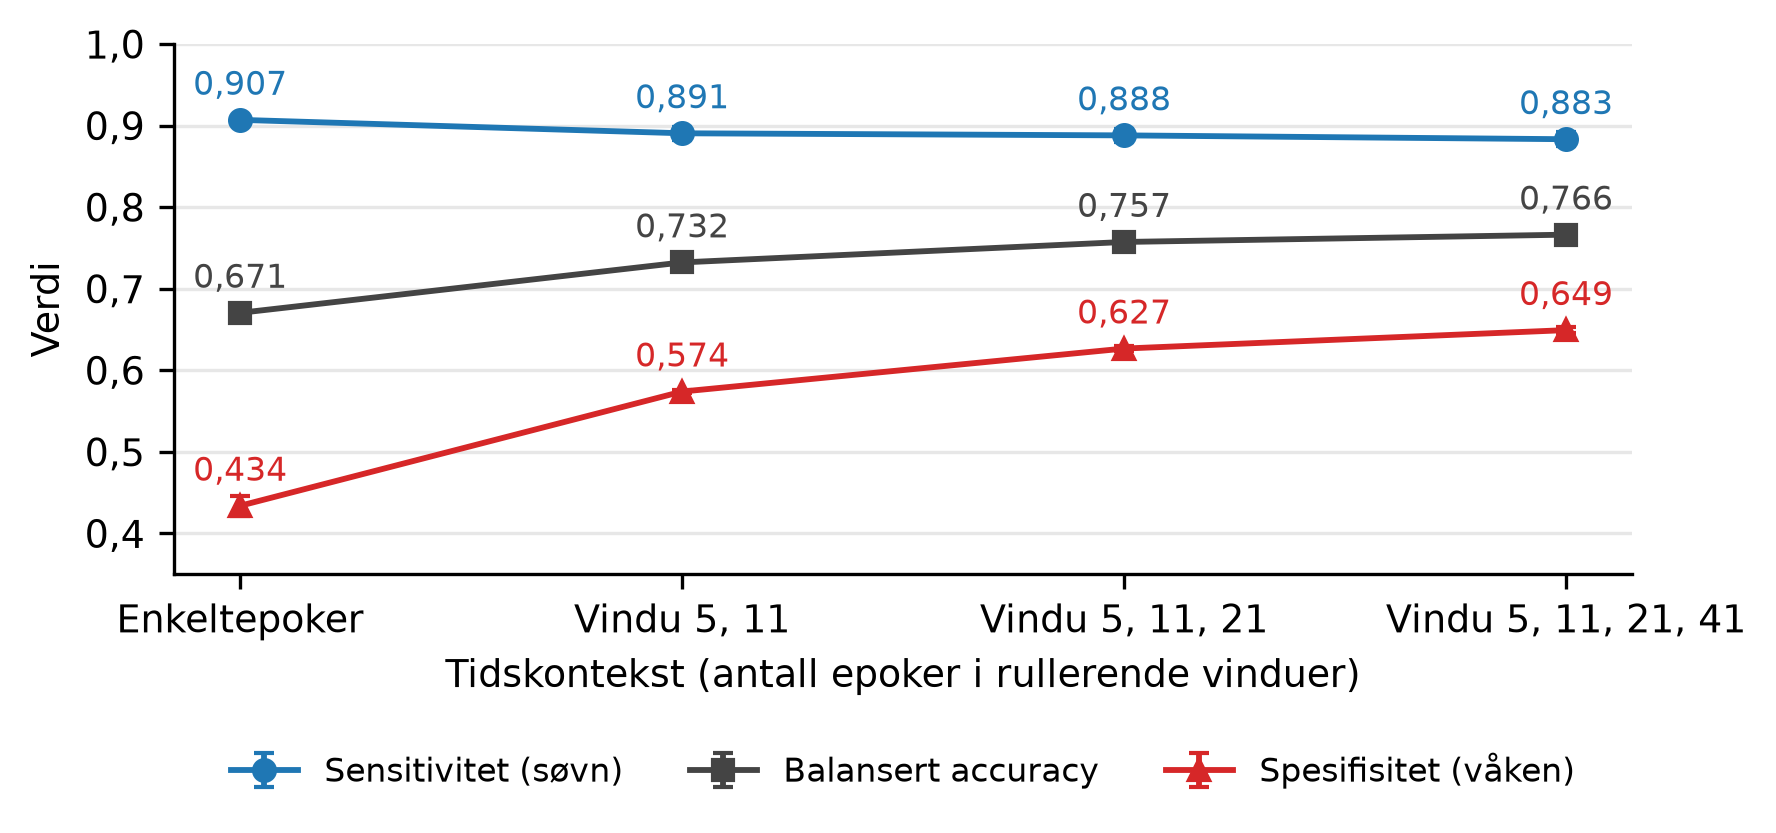

In [20]:
import matplotlib.pyplot as plt
os.makedirs('figures', exist_ok=True)
plt.rcParams['font.family'] = ['DejaVu Sans']   # første tilgjengelige brukes
plt.rcParams['font.size'] = 9

configs = {
    'Enkeltepoker':        base_nomiss,
    'Vindu 5, 11':         base_nomiss + ctx_for((5, 11)),
    'Vindu 5, 11, 21':     base_nomiss + ctx_for((5, 11, 21)),
    'Vindu 5, 11, 21, 41': base_nomiss + ctx_for((5, 11, 21, 41)),
}
fig1 = {}
for name, cols in configs.items():
    d = repeated_cv(cols, models2['LogReg'], Xtr3)
    fig1[name] = d.agg(['mean', 'std'])
    print(name, 'ferdig', flush=True)

metrics = [('sensitivitet_sovn', 'Sensitivitet (søvn)', '#1f77b4', 'o'),
           ('bal_acc', 'Balansert accuracy', '#444444', 's'),
           ('spesifisitet_vaken', 'Spesifisitet (våken)', '#d62728', '^')]
fig, ax = plt.subplots(figsize=(6.0, 3.0), dpi=300)
for col, label, color, marker in metrics:
    y  = [fig1[n].loc['mean', col] for n in configs]
    sd = [fig1[n].loc['std', col] for n in configs]
    ax.errorbar(range(len(y)), y, yerr=sd, label=label, color=color, marker=marker,
                markersize=5, linewidth=1.4, capsize=2.5)
    for i, v in enumerate(y):
        ax.annotate(f'{v:.3f}'.replace('.', ','), (i, v), textcoords='offset points',
                    xytext=(0, 6), ha='center', fontsize=8, color=color)
ax.set_xticks(range(len(configs))); ax.set_xticklabels(list(configs))
ax.set_ylim(0.35, 1.0)
ticks = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
ax.set_yticks(ticks); ax.set_yticklabels([f'{v:.1f}'.replace('.', ',') for v in ticks])
ax.set_ylabel('Verdi'); ax.set_xlabel('Tidskontekst (antall epoker i rullerende vinduer)')
ax.grid(axis='y', alpha=0.3)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=3, frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig('figures/figur1.png')
plt.show()

## 20. Tid siden PSG-start som feature
Walch et al. testet en tidsfeature (tid siden opptaksstart) som erstatning for en døgnrytmefeature. Her testes timer siden PSG-start som tilleggsfeature til den beste kontekstmodellen. Featuren bruker bare tiden som har gått siden opptaket startet, ikke total opptakslengde, og bruker dermed ikke informasjon fra resten av natten. Beslutningsregel (satt før kjøring): featuren beholdes hvis balansert accuracy øker med minst 0,01 og kappa ikke synker (gjennomsnitt over fem foldinndelinger). Reglen fastsetter også det endelige featuresettet (`FINAL_COLS`).

In [21]:
master3['hours_since_start'] = master3['epoch'] * EPOCH_SEC / 3600
Xtr3 = master3.iloc[tr]
Xte3 = master3.iloc[te]

feat_ctx  = base_nomiss + ctx_for((5, 11, 21, 41))
feat_time = feat_ctx + ['hours_since_start']

cmp_mean, cmp_txt = {}, {}
for name, cols in {'Kontekst 5-41': feat_ctx, '+ tid siden PSG-start': feat_time}.items():
    d = repeated_cv(cols, models2['LogReg'], Xtr3)
    cmp_mean[name] = d.mean()
    cmp_txt[name] = {c: f'{d[c].mean():.3f} ± {d[c].std():.3f}' for c in d.columns}
display(pd.DataFrame(cmp_txt).T)

a, b = cmp_mean['Kontekst 5-41'], cmp_mean['+ tid siden PSG-start']
use_time = (b['bal_acc'] - a['bal_acc'] >= 0.01) and (b['kappa'] >= a['kappa'])
FINAL_COLS = feat_time if use_time else feat_ctx
print('Endring balansert accuracy:', round(b['bal_acc'] - a['bal_acc'], 3),
      '| endring kappa:', round(b['kappa'] - a['kappa'], 3))
print('Tid siden start brukes:', use_time, '| antall features:', len(FINAL_COLS))

,bal_acc,sensitivitet_sovn,spesifisitet_vaken,f1_sovn,kappa,auc,ap_vaken
Kontekst 5-41,0.766 ± 0.003,0.883 ± 0.009,0.649 ± 0.004,0.922 ± 0.005,0.378 ± 0.016,0.819 ± 0.012,0.495 ± 0.010
+ tid siden PSG-start,0.785 ± 0.007,0.885 ± 0.008,0.685 ± 0.009,0.925 ± 0.005,0.402 ± 0.019,0.838 ± 0.010,0.518 ± 0.013


Endring balansert accuracy: 0.019 | endring kappa: 0.024
Tid siden start brukes: True | antall features: 23


## Beslutninger fastsatt før testsettet
- **Features:** 23 (seks enkeltepokefeatures, rullerende gjennomsnitt og standardavvik av log-varians og pulsgjennomsnitt over 5, 11, 21 og 41 epoker, og timer siden PSG-start). Valgt på kryssvalidering av utviklingsdeltakerne etter en regel fastsatt før kjøring.
- **Modell:** logistisk regresjon med klassevekting, medianimputering og standardisering. Ingen hyperparameterjustering.
- **Beslutningsterskel:** primært den som gir sensitivitet 0,90 i kryssvalideringen, sekundært den som maksimerer balansert accuracy. Terskel 0,5 vises som referanse.
- **Testsett:** de seks deltakerne 3997827, 4018081, 5498603, 6220552, 844359 og 9106476. Evalueres én gang. Usikkerhet beregnes med bootstrap over deltakere.
- Disse valgene endres ikke etter at testresultatene er sett.